<a href="https://colab.research.google.com/github/HamedKhosravi99/TrainYourAgent/blob/main/notebooks/02_policy_gradient_reinforce.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**TrainYourAgent** · [Ch 1 · Q-learning](https://colab.research.google.com/github/HamedKhosravi99/TrainYourAgent/blob/main/notebooks/01_q_learning_tool_agent.ipynb) → **📍 Ch 2 · REINFORCE** → [Ch 3 · GRPO](https://colab.research.google.com/github/HamedKhosravi99/TrainYourAgent/blob/main/notebooks/03_grpo_from_scratch.ipynb) → [Ch 4 · LLM + tools](https://colab.research.google.com/github/HamedKhosravi99/TrainYourAgent/blob/main/notebooks/04_llm_tool_use_grpo.ipynb)

# 🎲 Chapter 2 · Policy Gradients: teach the agent with *probabilities*

### Same tiny world. A brand-new kind of brain.

In [Chapter 1](https://colab.research.google.com/github/HamedKhosravi99/TrainYourAgent/blob/main/notebooks/01_q_learning_tool_agent.ipynb) our assistant kept a **scoreboard** (a Q-table) and pressed the button with the highest score.

That works for tiny worlds, but it is **not how language models work**. An LLM doesn't keep a score for every possible sentence. It produces **probabilities**: *"the next word is `the` with 31%, `a` with 12%, ..."*

**The mission:** keep the same assistant, the same four buttons and the same rewards, but replace the scoreboard with a **policy**, a list of probabilities for each situation. Then train it with **REINFORCE**, the simplest *policy-gradient* algorithm. REINFORCE is the ancestor of **PPO** and **GRPO**, the algorithms that train today's LLM agents.

✅ Free **CPU** · ✅ About 1 minute · ✅ No installations (PyTorch is pre-installed on Colab)

## 1 · Scores vs. probabilities 🤔

| | Chapter 1: Q-learning | Chapter 2: Policy gradient |
|:--|:--|:--|
| What the brain stores | a **score** for each button | a **probability** for each button |
| How it picks a button | highest score | rolls a **weighted die** 🎲 |
| How it explores | we had to add random moves (`explore=0.25`) | built in: unlikely buttons still get picked sometimes |
| What it learns from | each single step + a guess about the future | the **total reward of the whole episode** |
| Used to train LLMs? | rarely | **yes**: PPO and GRPO are policy-gradient methods |

The last row is why we're here. Everything in this notebook carries over, almost line for line, to training a real LLM in Chapter 4.

## 2 · Rebuild the tiny world 🌍

If you did Chapter 1, this will look familiar: the same buttons, tools, questions and reward rules, squeezed into a few cells.

In [1]:
import random
import torch
import matplotlib.pyplot as plt

random.seed(0)
torch.manual_seed(0)

buttons = ["Calculator", "Dictionary", "Reply", "Finish"]
topics = ["math", "words", "chat"]

In [2]:
meanings = {
    "orbit": "a path around another object",
    "habitat": "an animal's natural home",
    "gravity": "a force pulling things together",
}
greetings = {"hello": "Hello!", "thanks": "You're welcome!"}

def use_tool(button, task):
    kind, question, data = task
    if button == "Calculator" and kind == "math":
        return str(data[0] * data[1])
    if button == "Dictionary" and kind == "words":
        return meanings[data]
    if button == "Reply" and kind == "chat":
        return greetings[data]
    return None  # Wrong tool: no answer

In [3]:
practice = [
    ("math", "What is 3 x 4?", (3, 4)),
    ("math", "What is 6 x 8?", (6, 8)),
    ("words", "Define orbit", "orbit"),
    ("words", "Define habitat", "habitat"),
    ("chat", "Say hello", "hello"),
    ("chat", "Say thanks", "thanks"),
]
test_tasks = [  # never used for practice
    ("math", "What is 9 x 11?", (9, 11)),
    ("words", "Define gravity", "gravity"),
    ("chat", "Say hello to my friend", "hello"),
]

The world's rules are unchanged: **+1** for finishing with an answer, **−1** for finishing without one, **−0.15** for a wrong tool, **−0.02** for a useful tool.

In [4]:
def step(task, state, button, answer):
    topic, stage = state
    if button == "Finish":
        return state, (1 if answer else -1), True, answer
    result = use_tool(button, task)
    if result is not None:
        return (topic, "has_answer"), -0.02, False, result
    return state, -0.15, False, answer

## 3 · The new brain: a policy 🧠

For each of the six situations, the agent stores **four preference numbers**, one per button. They're called **logits**.

A function called **softmax** turns preferences into probabilities that add up to 100%. A bigger preference means a bigger probability.

At the start, every preference is **0**, so every button has the same 25% chance.

In [5]:
states = [(topic, stage) for topic in topics for stage in ("needs_tool", "has_answer")]
state_id = {state: i for i, state in enumerate(states)}

def new_policy():
    # 6 situations x 4 buttons, all starting at 0
    return torch.zeros(len(states), len(buttons), requires_grad=True)

policy = new_policy()
print(policy)

tensor([[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]], requires_grad=True)


`requires_grad=True` asks PyTorch to keep track of **how each number should change** to make the agent better. That's the "gradient" in *policy gradient*.

In [6]:
def probabilities(policy, state):
    return torch.softmax(policy[state_id[state]], dim=0)

print("Math, before training:", probabilities(policy, ("math", "needs_tool")))

Math, before training: tensor([0.2500, 0.2500, 0.2500, 0.2500], grad_fn=<SoftmaxBackward0>)


### 🔍 Try it: what does softmax do?

Change the preferences below and rerun. What happens when one number is much bigger than the others?

In [7]:
preferences = torch.tensor([2.0, 0.0, 0.0, 0.0])  # 👈 try [5, 0, 0, 0] or [1, 1, 1, 1]
for button, p in zip(buttons, torch.softmax(preferences, dim=0)):
    print(f"{button:10} {p:.0%}")

Calculator 71%
Dictionary 10%
Reply      10%
Finish     10%


### Picking a button = rolling a weighted die 🎲

During training the agent **samples** a button using its probabilities. Likely buttons come up often, and unlikely ones still come up sometimes. That's exploration, built right in!

For testing we can also let it be **greedy** and always pick the most likely button.

In [8]:
def choose_button(policy, state, greedy=False):
    p = probabilities(policy, state)
    if greedy:
        return int(p.argmax())
    return int(torch.multinomial(p, 1))

rolls = [buttons[choose_button(policy, ("math", "needs_tool"))] for _ in range(8)]
print("Eight rolls of an untrained agent:", rolls)

Eight rolls of an untrained agent: ['Reply', 'Reply', 'Finish', 'Calculator', 'Dictionary', 'Reply', 'Calculator', 'Dictionary']


## 4 · Play an episode and remember how likely each choice was 📝

To learn, the agent must remember **how likely each of its choices was**. We store the **log** of each probability (the *log-prob*).

Don't let the word "log" scare you. A log-prob is just "how likely was that choice?" on a different scale: **0** means *certain*, and very negative means *very unlikely*. LLM training code is full of log-probs, so it's worth meeting them now.

In [9]:
def run_episode(policy, task, greedy=False):
    state, answer = (task[0], "needs_tool"), None
    total_reward, log_probs, trail = 0.0, [], []
    for move in range(4):
        b = choose_button(policy, state, greedy)
        log_probs.append(torch.log(probabilities(policy, state)[b]))
        state, points, done, answer = step(task, state, buttons[b], answer)
        if move == 3 and not done:
            points -= 0.5  # Running out of moves is bad
        total_reward += points
        trail.append((buttons[b], points, answer))
        if done:
            break
    success = bool(done and answer)
    return total_reward, torch.stack(log_probs), success, trail

### Watch an untrained attempt 🍿

In [10]:
example = ("math", "What is 7 x 8?", (7, 8))
total, log_probs, success, trail = run_episode(policy, example)
for button, points, answer in trail:
    print(f"Pressed {button:10} | reward {points:+.2f} | answer: {answer}")
print(f"Total reward: {total:+.2f} | success: {success}")
print("Log-probs of its choices:", log_probs.detach().numpy().round(2))

Pressed Dictionary | reward -0.15 | answer: None
Pressed Finish     | reward -1.00 | answer: None
Total reward: -1.15 | success: False
Log-probs of its choices: [-1.39 -1.39]


Every choice so far had a 25% chance, so every log-prob is `log(0.25) ≈ −1.39`.

## 5 · The REINFORCE rule 🔁

This is the most important idea in the notebook. After every episode the agent asks **one question: did that go better or worse than usual?**

- **Better than usual** → make **every choice in that episode** more likely.
- **Worse than usual** → make every choice in it less likely.

"Usual" is a running average of recent rewards, called the **baseline**. The difference between this episode's reward and the baseline is called the **advantage**:

```
advantage = total_reward - baseline
loss      = -(advantage * sum_of_log_probs)
```

PyTorch then works out how to nudge each preference number (`loss.backward()`), and the optimizer applies the nudge (`optimizer.step()`).

💡 **Why the minus sign?** Optimizers always *minimize*. Minimizing `−(advantage × log-prob)` means *raising* the log-prob of choices that led to a positive advantage.

💡 **Notice:** the whole episode gets **one score**, and every choice in it shares the credit. LLM agent training does exactly the same thing. A whole answer, maybe hundreds of tokens and several tool calls, gets a single reward at the end.

In [11]:
def reinforce_update(optimizer, log_probs, total_reward, baseline):
    advantage = total_reward - baseline
    loss = -(advantage * log_probs.sum())
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

## 6 · Before learning: how good is it? 📏

Same fair test as Chapter 1: the **three unseen questions**, repeated 100 times each, with no learning.

In [12]:
def test_accuracy(policy, questions, repeats=100):
    with torch.no_grad():
        outcomes = [run_episode(policy, task)[2]
                    for task in questions for _ in range(repeats)]
    return sum(outcomes) / len(outcomes)

before = test_accuracy(policy, test_tasks)
print(f"Before training: {before:.0%} of tasks completed")

Before training: 19% of tasks completed


## 7 · Time to train! 🎯

Each round: pick a practice question → play an episode → apply the REINFORCE rule → update the baseline.

We'll also record the probability of the **right first button for math** (Calculator) and the **right second button** (Finish), so we can watch the brain change.

In [13]:
TRAIN_ROUNDS = 600   # 👈 try 100 or 1000
LEARNING_RATE = 0.1  # 👈 try 0.01 or 0.5

policy = new_policy()
optimizer = torch.optim.Adam([policy], lr=LEARNING_RATE)
baseline = 0.0
history, p_calculator, p_finish = [], [], []

for round_number in range(TRAIN_ROUNDS):
    task = random.choice(practice)
    total, log_probs, success, _ = run_episode(policy, task)
    reinforce_update(optimizer, log_probs, total, baseline)
    baseline = 0.9 * baseline + 0.1 * total  # running average

    history.append(int(success))
    with torch.no_grad():
        p_calculator.append(probabilities(policy, ("math", "needs_tool"))[0].item())
        p_finish.append(probabilities(policy, ("math", "has_answer"))[3].item())
print("Practice complete! 🎉")

Practice complete! 🎉


### Watch the probabilities grow 📈

**Left:** the share of successful practice rounds among the most recent 30 tries.
**Right:** how likely the agent is to press the right buttons for a math question. Both start at 25%, a blind guess.

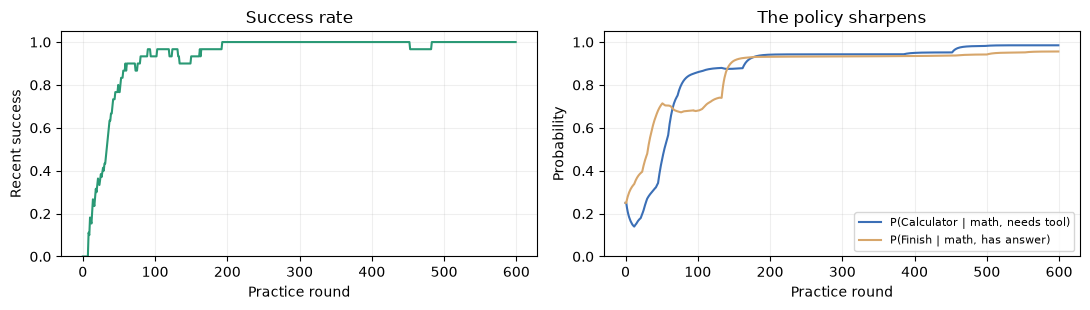

In [14]:
recent = [sum(history[max(0, i-29):i+1]) / min(30, i+1) for i in range(len(history))]
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.2))
left.plot(recent, color="#2A9975")
left.set(ylim=(0, 1.05), xlabel="Practice round", ylabel="Recent success",
         title="Success rate")
right.plot(p_calculator, label="P(Calculator | math, needs tool)", color="#3B6FB6")
right.plot(p_finish, label="P(Finish | math, has answer)", color="#D7A66B")
right.set(ylim=(0, 1.05), xlabel="Practice round", ylabel="Probability",
          title="The policy sharpens")
right.legend(loc="lower right", fontsize=8)
for ax in (left, right):
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 8 · Peek inside the brain 🔎

Each row is a situation; each column is a button. Darker = more likely.

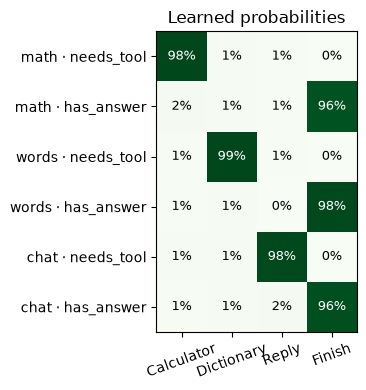

In [15]:
with torch.no_grad():
    table = torch.softmax(policy, dim=1).numpy()
fig, ax = plt.subplots(figsize=(7, 4))
ax.imshow(table, cmap="Greens", vmin=0, vmax=1)
ax.set_xticks(range(len(buttons)), buttons, rotation=20)
ax.set_yticks(range(len(states)), [f"{t} · {s}" for t, s in states])
for i in range(len(states)):
    for j in range(len(buttons)):
        ax.text(j, i, f"{table[i, j]:.0%}", ha="center", va="center",
                color="white" if table[i, j] > 0.6 else "black", fontsize=9)
ax.set_title("Learned probabilities")
plt.tight_layout()
plt.show()

The agent learned the same two-step plan as in Chapter 1 (**right tool → Finish**), but this time as **probabilities**, not scores.

## 9 · The big reveal: before vs. after 🏆

Before: 19% completed
After:  99% completed


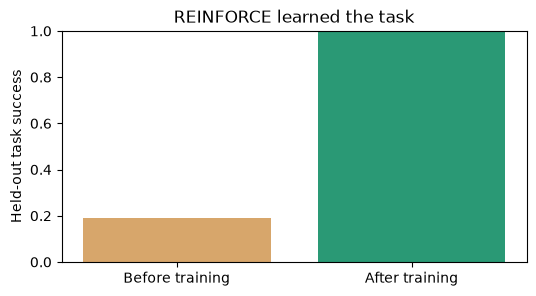

In [16]:
after = test_accuracy(policy, test_tasks)
print(f"Before: {before:.0%} completed")
print(f"After:  {after:.0%} completed")

plt.figure(figsize=(6, 3))
plt.bar(["Before training", "After training"], [before, after], color=["#D7A66B", "#2A9975"])
plt.ylim(0, 1)
plt.ylabel("Held-out task success")
plt.title("REINFORCE learned the task")
plt.show()

## 10 · Why subtract a baseline? An experiment 🧪

Imagine a very generous teacher who hands out **+3 bonus points for every episode**, even terrible ones.

- **Without a baseline**, every episode now looks "good", so the agent reinforces its *mistakes* too. It can still tell good from bad, but only faintly.
- **With a baseline**, the bonus quickly becomes part of "usual", and only *better-than-usual* episodes get reinforced.

Let's test it. We train 8 fresh agents for each setting and average their learning curves. This takes about 20 seconds.

In [17]:
def train_agent(rounds=300, bonus=0.0, use_baseline=True, seed=0):
    random.seed(seed)
    torch.manual_seed(seed)
    policy = new_policy()
    optimizer = torch.optim.Adam([policy], lr=0.1)
    baseline, wins = 0.0, []
    for _ in range(rounds):
        total, log_probs, success, _ = run_episode(policy, random.choice(practice))
        total += bonus
        reinforce_update(optimizer, log_probs, total, baseline if use_baseline else 0.0)
        baseline = 0.9 * baseline + 0.1 * total
        wins.append(success)
    return policy, wins

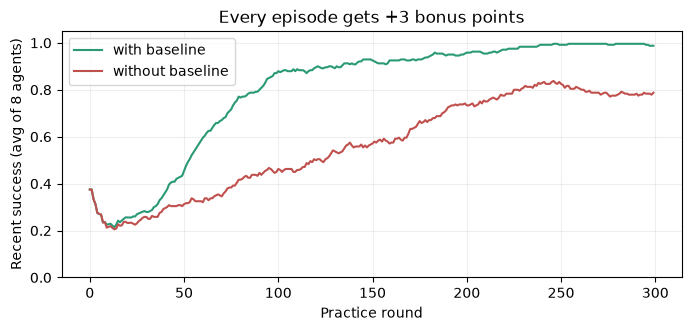

In [18]:
def smooth(wins, window=30):
    return [sum(wins[max(0, i-window+1):i+1]) / min(window, i+1) for i in range(len(wins))]

plt.figure(figsize=(8, 3.2))
for use_baseline, color in [(True, "#2A9975"), (False, "#C0504D")]:
    curves = [smooth(train_agent(bonus=3.0, use_baseline=use_baseline, seed=s)[1]) for s in range(8)]
    mean_curve = [sum(c[i] for c in curves) / len(curves) for i in range(len(curves[0]))]
    label = "with baseline" if use_baseline else "without baseline"
    plt.plot(mean_curve, color=color, label=label)
plt.ylim(0, 1.05)
plt.xlabel("Practice round")
plt.ylabel("Recent success (avg of 8 agents)")
plt.title("Every episode gets +3 bonus points")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

**What you should see:** the green curve (with a baseline) climbs to nearly 100%, while the red curve (without one) crawls up much more slowly.

**Takeaway:** a baseline doesn't change *what* is good. It makes the signal **clearer**. In the next chapter, **GRPO** uses an even smarter baseline: it lets the agent try **the same question several times** and compares the attempts *with each other*.

## 11 · Your turn: three small experiments 🧪

1. **Learning rate:** Change `LEARNING_RATE = 0.1` to `0.01`. How many rounds does it need now? What about `0.5`?
2. **Mean teacher:** In the experiment, change `bonus=3.0` to `bonus=-3.0`. Does the baseline still help?
3. **Short practice:** Set `TRAIN_ROUNDS = 100`. Look at the heatmap: which situation is learned last, and why?

After changing an earlier cell, use **Runtime → Restart and run all** to get a clean experiment.

## 12 · How this connects to LLM agentic RL 🚀

| In this notebook | In LLM agentic RL (Chapter 4) |
|:--|:--|
| Choose one of 4 buttons | Choose one of ~150,000 tokens |
| Softmax over 4 preferences | Softmax over the model's output logits |
| One episode = a few button presses | One episode = a whole answer with tool calls |
| Total reward for the episode | One reward for the whole answer (e.g. "is the final number correct?") |
| `loss = -(advantage * log_probs.sum())` | **The same line**, summed over the answer's tokens |

That one line is the heart of how LLMs are trained with RL. Everything else is about making it **stable and efficient**, which is exactly what **GRPO** adds in Chapter 3.

## 🎓 Congratulations: you trained a policy-gradient agent!

You learned:

- ✅ **Policies:** an agent can learn *probabilities* instead of scores.
- ✅ **Softmax and log-probs:** how preferences become probabilities and how we measure "how likely was that?"
- ✅ **REINFORCE:** make better-than-usual episodes more likely, worse-than-usual ones less likely.
- ✅ **Baselines:** comparing against "usual" makes learning faster and steadier.

**Your one-sentence takeaway:** *Policy gradients nudge the probabilities of an agent's choices up or down depending on whether the episode beat expectations.*

### ➡️ Next: [Ch 3 · GRPO](https://colab.research.google.com/github/HamedKhosravi99/TrainYourAgent/blob/main/notebooks/03_grpo_from_scratch.ipynb)

<a href="https://colab.research.google.com/github/HamedKhosravi99/TrainYourAgent/blob/main/notebooks/03_grpo_from_scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

⭐ Found this useful? [Star TrainYourAgent on GitHub](https://github.com/HamedKhosravi99/TrainYourAgent) so other beginners can find it.